# Cámara IA · Figuras geométricas
Adaptación del ejemplo de clase. Entrena una CNN con las imágenes etiquetadas de [Four Shapes](https://www.kaggle.com/datasets/smeschke/four-shapes) y busca una figura con la webcam desde Colab. Ejecuta las celdas en orden. Para la primera sesión basta con comprobar los datos. Una GPU es opcional para acelerar el entrenamiento.

## 1. Cargar y comprobar las cuatro clases

In [ ]:
from pathlib import Path
import subprocess
import sys
try:
    import kagglehub
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

carpeta = Path(kagglehub.dataset_download("smeschke/four-shapes"))
clases = ["circle", "square", "star", "triangle"]
raices = [p for p in [carpeta, *carpeta.rglob("circle")]
          if p == carpeta or p.is_dir()]
candidatas = [carpeta, *[p.parent for p in raices if p.name == "circle"]]
raiz = next(p for p in candidatas if all((p / c).is_dir() for c in clases))
for clase in clases:
    archivos = [p for p in (raiz/clase).rglob("*") if p.suffix.lower() in {".png",".jpg",".jpeg",".bmp",".gif"}]
    print(clase, len(archivos), "imágenes")
    assert archivos, f"Carpeta vacía: {clase}"

100%|██████████| 21.6M/21.6M [00:00<00:00, 35.7MB/s]

Extracting files...


circle 3720 imágenes
square 3765 imágenes
star 3765 imágenes
triangle 3720 imágenes


## 2. Preparar imágenes y entrenar según el ejemplo de clase

In [ ]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(42)
print("Versión de TensorFlow:", tf.__version__)   # usar la misma versión al correr la cámara en local

Versión de TensorFlow: 2.21.0


### Preparar el dataset

Las imágenes se cargan en escala de grises y se reducen a $64\times64$ píxeles. Después se dividen de forma estratificada en **entrenamiento (70 %)**, **validación (15 %)** y **prueba (15 %)**, y se normalizan los píxeles al intervalo $[0,1]$ con

$$x' = \frac{x}{255}$$

In [ ]:
IMG = 64

completo = tf.keras.utils.image_dataset_from_directory(
    raiz, class_names=clases, image_size=(IMG, IMG), color_mode="grayscale",
    batch_size=None, shuffle=False)
class_names = completo.class_names
print("Clases (orden usado por la red):", class_names)

X, y = [], []
for lote_x, lote_y in completo.batch(1000):
    X.append(lote_x.numpy())
    y.append(lote_y.numpy())
X = np.concatenate(X).astype("float32")
y = np.concatenate(y)

train_images, temp_images, train_labels, temp_labels = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
val_images, test_images, val_labels, test_labels = train_test_split(
    temp_images, temp_labels, test_size=0.50, stratify=temp_labels, random_state=42)

# Normalizar los valores de pixel para que estén entre 0 y 1
train_images, val_images, test_images = train_images / 255.0, val_images / 255.0, test_images / 255.0

print("Entrenamiento:", train_images.shape, "| Validación:", val_images.shape, "| Prueba:", test_images.shape)

Found 14970 files belonging to 4 classes.
Clases (orden usado por la red): ['circle', 'square', 'star', 'triangle']
Entrenamiento: (10479, 64, 64, 1) | Validación: (2245, 64, 64, 1) | Prueba: (2246, 64, 64, 1)


### Verificar los datos

Se grafican las primeras 25 imágenes del conjunto de entrenamiento con su clase debajo. **Importante:** conviene fijarse en cómo se ven las figuras (color y fondo), porque la cámara en vivo debe producir imágenes equivalentes.

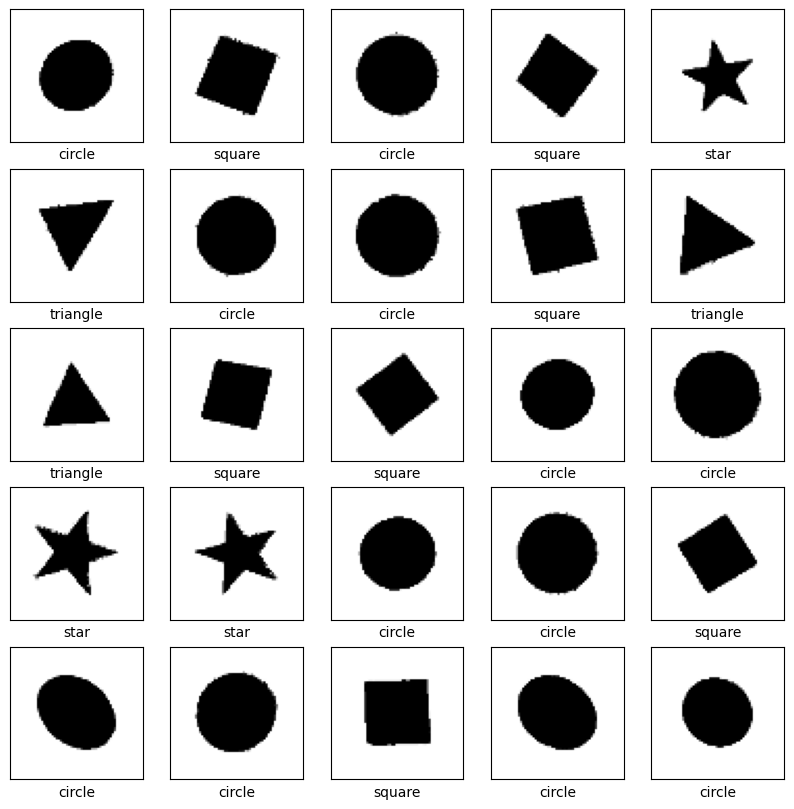

In [ ]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i].squeeze(), cmap="gray")
    plt.xlabel(class_names[train_labels[i]])
plt.show()

### Crear la base convolucional

La entrada de la red es un tensor de forma $(64, 64, 1)$: alto, ancho y canales (escala de grises). La base convolucional apila capas `Conv2D` y `MaxPooling2D`. Con un filtro de tamaño $k\times k$ sin relleno, el tamaño de salida por lado es

$$n_{\text{salida}} = n - k + 1$$

y cada `MaxPooling2D` de $2\times2$ divide el tamaño entre 2. En esta red: $64 \to 62 \to 31 \to 29 \to 14 \to 12$.

Las tres primeras capas realizan **aumento de datos** (rotación, zoom y desplazamiento aleatorios). Solo actúan durante el entrenamiento y ayudan a que el modelo tolere variaciones de posición frente a la cámara.

In [ ]:
model = models.Sequential()
model.add(layers.Input(shape=(IMG, IMG, 1)))

# Aumento de datos (solo activo al entrenar)
model.add(layers.RandomRotation(0.1, fill_mode="nearest"))
model.add(layers.RandomZoom(0.1, fill_mode="nearest"))
model.add(layers.RandomTranslation(0.1, 0.1, fill_mode="nearest"))

# Base convolucional
model.add(layers.Conv2D(32, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 64, 64, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,744 (217.75 KB)

 Trainable params: 55,744 (217.75 KB)

 Non-trainable params: 0 (0.00 B)

### Añadir capas Dense

El último tensor de la base convolucional tiene forma $(12, 12, 64)$. Se aplana a un vector de $12\cdot12\cdot64 = 9216$ valores y se conecta a capas `Dense`. La capa final tiene 4 salidas (una por figura) y entrega *logits* $z_i$.

In [ ]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(4))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 64, 64, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       589,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 645,892 (2.46 MB)

 Trainable params: 645,892 (2.46 MB)

 Non-trainable params: 0 (0.00 B)

### Compilar y entrenar el modelo

Se usa el optimizador **Adam** y la entropía cruzada categórica dispersa. Para la clase verdadera $y$:

$$L = -\log(p_y), \qquad p_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

Como la última capa entrega logits (sin *softmax*), se indica `from_logits=True`.

In [ ]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

history = model.fit(train_images, train_labels, epochs=10, batch_size=32,
                    validation_data=(val_images, val_labels))

Epoch 1/10
328/328 ━━━━━━━━━━━━━━━━━━━━ 70s 204ms/step - accuracy: 0.8852 - loss: 0.2570 - val_accuracy: 1.0000 - val_loss: 6.4659e-04
Epoch 2/10
328/328 ━━━━━━━━━━━━━━━━━━━━ 63s 191ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 1.0000 - val_loss: 2.4108e-04
Epoch 3/10
 20/328 ━━━━━━━━━━━━━━━━━━━━ 1:14 243ms/step - accuracy: 1.0000 - loss: 3.4043e-04

KeyboardInterrupt: 

### Evaluar el modelo

Se grafican la exactitud (*accuracy*) y la pérdida (*loss*) por época, para entrenamiento y validación. Una brecha grande entre ambas curvas indica sobreajuste. Después se mide la exactitud final con el conjunto de prueba, que la red no vio durante el entrenamiento.

NameError: name 'history' is not defined

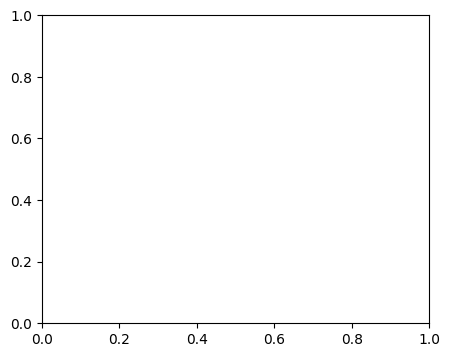

In [ ]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.show()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print("Exactitud en el conjunto de prueba:", test_acc)

### Matriz de confusión

Muestra qué figuras se confunden entre sí. La diagonal principal contiene los aciertos.

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

logits = model.predict(test_images, verbose=0)
pred = np.argmax(logits, axis=1)

ConfusionMatrixDisplay(confusion_matrix(test_labels, pred),
                       display_labels=class_names).plot(cmap="Blues")
plt.show()

## 3. Guardar una copia del modelo
Descarga el archivo si quieres conservar los pesos al cerrar el entorno. La exactitud con imágenes reservadas de Kaggle y el rendimiento de la webcam son dos mediciones distintas.

In [ ]:
from google.colab import files
model.save("modelo_figuras.keras")
files.download("modelo_figuras.keras")

## 4. Buscar una figura con la webcam
Prepara figuras rellenas de cartulina verde y un fondo liso de otro color. Deja espacio entre figuras. El navegador pide permiso al pulsar Buscar. OpenCV localiza regiones verdes y la CNN clasifica su forma. Elige la figura, pulsa Buscar y muévela a un lado. La dirección calculada es una salida visual para una futura integración con los servos. Pulsa Apagar al terminar.

In [1]:
# Punto 4. Buscar una figura con la webcam en Google Colab

import base64
import json
from pathlib import Path
from uuid import uuid4

import cv2
import numpy as np
import tensorflow as tf
from google.colab import files, output
from IPython.display import display, Javascript, JSON


# 1. Recuperar la red entrenada
if "model" not in globals() or model is None:
    ruta_modelo = Path("/content/modelo_figuras.keras")

    if not ruta_modelo.is_file():
        print("Selecciona modelo_figuras.keras desde tu carpeta Descargas.")
        archivos = files.upload()
        ruta_modelo = next(
            (Path(nombre) for nombre in archivos
             if nombre.lower().endswith(".keras")),
            None
        )
        if ruta_modelo is None:
            raise ValueError("Ejecuta la celda otra vez y elige el archivo .keras.")

    model = tf.keras.models.load_model(ruta_modelo, compile=False)

# Mismo tamaño y orden de clases que usaste al entrenar
IMG = 64
clases_figuras = ["circle", "square", "star", "triangle"]
nombres_figuras = {
    "circle": "Círculo",
    "square": "Cuadrado",
    "star": "Estrella",
    "triangle": "Triángulo",
}

if tuple(model.input_shape[1:]) != (64, 64, 1) or model.output_shape[-1] != 4:
    raise ValueError("Revisa que el archivo sea el modelo de las cuatro figuras.")

print("Modelo listo para la cámara.")


# 2. Localizar las figuras verdes y clasificarlas con la red
def buscar_figura(imagen_jpeg, objetivo):
    datos = base64.b64decode(imagen_jpeg.split(",", 1)[1])
    cuadro = cv2.imdecode(np.frombuffer(datos, np.uint8), cv2.IMREAD_COLOR)

    hsv = cv2.cvtColor(cuadro, cv2.COLOR_BGR2HSV)
    mascara = cv2.inRange(hsv, (35, 60, 40), (90, 255, 255))
    contornos, _ = cv2.findContours(
        mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    entradas = []
    cajas = []

    for contorno in contornos:
        if cv2.contourArea(contorno) < 500:
            continue

        x, y, ancho, alto = cv2.boundingRect(contorno)

        # Preparar la figura como en las fotos de entrenamiento:
        # silueta negra centrada sobre fondo blanco.
        mayor = max(ancho, alto)
        lado = mayor + max(2, round(mayor * 0.12))
        silueta = np.full((lado, lado), 255, dtype=np.uint8)

        desplazamiento = (
            (lado - ancho) // 2 - x,
            (lado - alto) // 2 - y,
        )
        cv2.drawContours(
            silueta, [contorno], 0, 0, -1, offset=desplazamiento
        )
        entrada = cv2.resize(silueta, (IMG, IMG), interpolation=cv2.INTER_AREA)
        entradas.append(entrada)
        cajas.append([x, y, ancho, alto])

    respuesta = {"texto": "Buscando " + nombres_figuras[objetivo], "caja": None}

    if entradas:
        lote = np.asarray(entradas, dtype=np.float32)[..., None] / 255.0
        probabilidades = tf.nn.softmax(model(lote, training=False), axis=-1).numpy()
        mejor_confianza = 0.0

        for caja, valores in zip(cajas, probabilidades):
            indice = int(np.argmax(valores))
            confianza = float(valores[indice])

            if clases_figuras[indice] != objetivo or confianza < 0.80:
                continue
            if confianza <= mejor_confianza:
                continue

            mejor_confianza = confianza
            x, y, ancho, alto = caja
            dx = (x + ancho / 2) / cuadro.shape[1] - 0.5
            dy = (y + alto / 2) / cuadro.shape[0] - 0.5

            direccion = []
            if abs(dx) > 0.10:
                direccion.append("izquierda" if dx < 0 else "derecha")
            if abs(dy) > 0.10:
                direccion.append("arriba" if dy < 0 else "abajo")

            posicion = " y ".join(direccion) or "centrado"
            respuesta = {
                "texto": f"{nombres_figuras[objetivo]} · {confianza:.0%} · {posicion}",
                "caja": caja,
            }

    return JSON(respuesta)


# 3. Conectar el panel del navegador con la función de Python
clave = "camara_figuras_" + uuid4().hex
output.register_callback(clave, buscar_figura)


# 4. Mostrar video en vivo y dibujar el resultado sobre él
panel = r"""
(() => {
  const panel = document.createElement('section');
  panel.innerHTML = `
    <label>Figura
      <select>
        <option value="circle">Círculo</option>
        <option value="square">Cuadrado</option>
        <option value="star">Estrella</option>
        <option value="triangle">Triángulo</option>
      </select>
    </label>
    <button class="buscar">Buscar</button>
    <button class="apagar">Apagar</button>
    <p>Elige una figura y pulsa Buscar.</p>
    <div style="position:relative;width:100%;max-width:640px">
      <video autoplay muted playsinline style="display:block;width:100%"></video>
      <canvas style="position:absolute;inset:0;width:100%;height:100%;
                     pointer-events:none"></canvas>
    </div>`;
  document.body.appendChild(panel);

  const video = panel.querySelector('video');
  const capa = panel.querySelector('canvas');
  const dibujo = capa.getContext('2d');
  const foto = document.createElement('canvas');
  const captura = foto.getContext('2d');
  const selector = panel.querySelector('select');
  const botonBuscar = panel.querySelector('.buscar');
  const estado = panel.querySelector('p');

  let sesion = 0;
  let seleccion = 0;

  function limpiar() {
    dibujo.clearRect(0, 0, capa.width, capa.height);
  }

  function apagar() {
    sesion++;
    if (video.srcObject) {
      video.srcObject.getTracks().forEach(pista => pista.stop());
    }
    video.srcObject = null;
    botonBuscar.disabled = false;
    limpiar();
    estado.textContent = 'Cámara apagada.';
  }

  panel.querySelector('.apagar').onclick = apagar;
  window.addEventListener('pagehide', apagar, {once: true});

  selector.onchange = () => {
    seleccion++;
    limpiar();
    if (video.srcObject) estado.textContent = 'Buscando la nueva figura…';
  };

  botonBuscar.onclick = async () => {
    const turno = ++sesion;
    botonBuscar.disabled = true;
    estado.textContent = 'Abriendo cámara…';

    try {
      const stream = await navigator.mediaDevices.getUserMedia({
        video: {width: {ideal: 640}, height: {ideal: 480}},
        audio: false
      });

      if (turno !== sesion) {
        stream.getTracks().forEach(pista => pista.stop());
        return;
      }

      video.srcObject = stream;
      await video.play();
      if (turno !== sesion) return;

      foto.width = capa.width = 640;
      foto.height = capa.height =
        Math.round(640 * video.videoHeight / video.videoWidth);

      google.colab.output.setIframeHeight(
        document.documentElement.scrollHeight, true
      );

      while (turno === sesion) {
        const revision = seleccion;
        const figura = selector.value;

        captura.drawImage(video, 0, 0, foto.width, foto.height);
        const respuesta = await google.colab.kernel.invokeFunction(
          __CLAVE__, [foto.toDataURL('image/jpeg', 0.75), figura], {}
        );

        if (turno !== sesion) return;
        if (revision !== seleccion) continue;

        const dato = respuesta.data['application/json'];
        if (!dato) throw Error('Colab no devolvió una predicción.');

        limpiar();
        if (dato.caja) {
          dibujo.strokeStyle = '#13dc73';
          dibujo.lineWidth = 3;
          dibujo.strokeRect(...dato.caja);
        }
        estado.textContent = dato.texto;
      }
    } catch (error) {
      if (turno === sesion) {
        apagar();
        estado.textContent = error.message;
      }
    }
  };
})();
"""

display(Javascript(panel.replace("__CLAVE__", json.dumps(clave))))

Selecciona modelo_figuras.keras desde tu carpeta Descargas.


Saving modelo_figuras.keras to modelo_figuras.keras
Modelo listo para la cámara.


<IPython.core.display.Javascript object>

In [2]:
def buscar_con_orden(imagen_jpeg, objetivo):
    resultado = buscar_figura(imagen_jpeg, objetivo).data.copy()
    caja = resultado["caja"]

    if caja is None:
        orden = "En espera"
    else:
        x, y, ancho, alto = caja
        centro_x = x + ancho / 2

        # El Punto 4 envía imágenes de 640 píxeles de ancho.
        # Entre el 40 % y el 60 % consideramos la figura centrada.
        if centro_x < 640 * 0.40:
            orden = "+ (girar a la izquierda)"
        elif centro_x > 640 * 0.60:
            orden = "- (girar a la derecha)"
        else:
            orden = "Mantener posición"

    resultado["texto"] += " | Orden horizontal: " + orden
    return JSON(resultado)

output.register_callback(clave, buscar_con_orden)
print("Prueba horizontal lista. Usa el botón Buscar del Punto 4.")

Prueba horizontal lista. Usa el botón Buscar del Punto 4.


In [3]:
clave_prueba = "prueba_horizontal_" + uuid4().hex
output.register_callback(clave_prueba, buscar_con_orden)
display(Javascript(panel.replace("__CLAVE__", json.dumps(clave_prueba))))

<IPython.core.display.Javascript object>

In [4]:
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from threading import Thread
from html import escape
from google.colab import output
from IPython.display import HTML, display

pagina_usb = """
<!doctype html>
<html lang="es">
<meta charset="utf-8">
<title>Prueba USB de Cámara IA</title>
<h2>Prueba de conexión con Arduino</h2>
<button id="conectar">Conectar Arduino</button>
<p id="estado">Arduino pendiente de conexión.</p>
<script>
const boton = document.querySelector("#conectar");
const estado = document.querySelector("#estado");

boton.onclick = async () => {
  boton.disabled = true;
  let puerto;
  let abierto = false;

  try {
    if (!navigator.serial) {
      throw new Error("Esta pestaña no tiene acceso al puerto serie.");
    }
    puerto = await navigator.serial.requestPort();
    await puerto.open({ baudRate: 9600 });
    abierto = true;
    await puerto.close();
    abierto = false;
    estado.textContent = "Conexión USB correcta. Puerto liberado.";
  } catch (error) {
    estado.textContent = error.name + ": " + error.message;
  } finally {
    if (abierto) await puerto.close().catch(() => {});
    boton.disabled = false;
  }
};
</script>
</html>
"""

class PaginaUSB(BaseHTTPRequestHandler):
    def do_GET(self):
        datos = pagina_usb.encode("utf-8")
        self.send_response(200)
        self.send_header("Content-Type", "text/html; charset=utf-8")
        self.send_header("Content-Length", str(len(datos)))
        self.end_headers()
        self.wfile.write(datos)

    def log_message(self, *args):
        pass

if "servidor_usb" in globals():
    servidor_usb.shutdown()
    servidor_usb.server_close()

servidor_usb = ThreadingHTTPServer(("127.0.0.1", 0), PaginaUSB)
Thread(target=servidor_usb.serve_forever, daemon=True).start()

url_usb = output.eval_js(
    f"google.colab.kernel.proxyPort({servidor_usb.server_port})"
)
display(HTML(
    f'<a href="{escape(url_usb, quote=True)}" target="_blank" rel="noopener">'
    'Abrir prueba USB en otra pestaña</a>'
))

In [5]:
pagina_usb = """
<!doctype html>
<html lang="es">
<meta charset="utf-8">
<title>Prueba de giro</title>
<h2>Prueba del servo horizontal</h2>
<button id="girar">Probar giro a la izquierda</button>
<p id="estado">Listo para la prueba.</p>

<script>
const boton = document.querySelector("#girar");
const estado = document.querySelector("#estado");
const esperar = ms => new Promise(resolve => setTimeout(resolve, ms));

boton.onclick = async () => {
  boton.disabled = true;
  let puerto;
  let abierto = false;

  try {
    puerto = await navigator.serial.requestPort();
    await puerto.open({ baudRate: 9600 });
    abierto = true;
    estado.textContent = "Esperando a que arranque el Arduino…";
    await esperar(3000);

    const escritor = puerto.writable.getWriter();
    try {
      await escritor.write(new TextEncoder().encode("+"));
    } finally {
      escritor.releaseLock();
    }

    await esperar(600);
    estado.textContent = "Orden + enviada. Revisa el giro horizontal.";
  } catch (error) {
    estado.textContent = error.name + ": " + error.message;
  } finally {
    if (abierto) await puerto.close().catch(() => {});
    boton.disabled = false;
  }
};
</script>
</html>
"""

print("Página actualizada. Regresa a la pestaña de prueba USB y pulsa Ctrl + R.")

Página actualizada. Regresa a la pestaña de prueba USB y pulsa Ctrl + R.


In [6]:
from time import monotonic
from urllib.parse import urlsplit, parse_qs

# Guardar la posición más reciente del círculo que ve el panel.
ultima_lectura = (0.0, "")

def observar_para_giro(imagen_jpeg, objetivo):
    global ultima_lectura
    resultado = buscar_con_orden(imagen_jpeg, objetivo).data.copy()
    orden = ""

    if objetivo == "circle" and resultado["caja"] is not None:
        x, y, ancho, alto = resultado["caja"]
        centro_x = x + ancho / 2
        if centro_x < 256:
            orden = "+"  # Izquierda
        elif centro_x > 384:
            orden = "-"  # Derecha
        else:
            orden = "centro"

    ultima_lectura = (monotonic(), orden)
    return JSON(resultado)

# Crear un panel de cámara asociado a esta prueba.
clave_giro = "giro_circulo_" + uuid4().hex
output.register_callback(clave_giro, observar_para_giro)

pagina_usb = """
<!doctype html>
<html lang="es">
<meta charset="utf-8">
<title>Prueba con el círculo</title>
<h2>Giro según la posición del círculo</h2>
<button id="probar">Hacer un giro de prueba</button>
<p id="estado">Coloca el círculo a un lado antes de pulsar.</p>
<script>
const boton = document.querySelector("#probar");
const estado = document.querySelector("#estado");
const esperar = ms => new Promise(resolve => setTimeout(resolve, ms));

boton.onclick = async () => {
  boton.disabled = true;
  let puerto;
  let abierto = false;
  try {
    puerto = await navigator.serial.requestPort();
    await puerto.open({baudRate: 9600});
    abierto = true;
    estado.textContent = "Preparando Arduino. Mantén quieto el círculo…";
    await esperar(3000);

    const url = new URL(location.href);
    url.searchParams.set("lectura", "1");
    const respuesta = await fetch(url, {cache: "no-store"});
    if (!respuesta.ok) throw Error("No se pudo consultar la cámara.");
    const dato = await respuesta.json();

    if (dato.orden === "+" || dato.orden === "-") {
      const escritor = puerto.writable.getWriter();
      try {
        await escritor.write(new TextEncoder().encode(dato.orden));
      } finally {
        escritor.releaseLock();
      }
      await esperar(600);
      estado.textContent = dato.orden === "+"
        ? "Círculo a la izquierda. Orden + enviada."
        : "Círculo a la derecha. Orden - enviada.";
    } else {
      estado.textContent = dato.mensaje;
    }
  } catch (error) {
    estado.textContent = error.message;
  } finally {
    if (abierto) await puerto.close().catch(() => {});
    boton.disabled = false;
  }
};
</script>
</html>
"""

def servir_prueba(self):
    consulta = parse_qs(urlsplit(self.path).query)
    if consulta.get("lectura") == ["1"]:
        instante, orden = ultima_lectura
        if monotonic() - instante > 2 or not orden:
            dato = {"orden": "", "mensaje": "Sin detección reciente del círculo."}
        else:
            dato = {"orden": orden, "mensaje": "Círculo centrado. Mantener posición."}
        contenido = json.dumps(dato).encode("utf-8")
        tipo = "application/json"
    else:
        contenido = pagina_usb.encode("utf-8")
        tipo = "text/html"

    self.send_response(200)
    self.send_header("Content-Type", tipo + "; charset=utf-8")
    self.send_header("Cache-Control", "no-store")
    self.send_header("Content-Length", str(len(contenido)))
    self.end_headers()
    self.wfile.write(contenido)

PaginaUSB.do_GET = servir_prueba
display(Javascript(panel.replace("__CLAVE__", json.dumps(clave_giro))))

<IPython.core.display.Javascript object>

In [7]:
from time import monotonic, sleep
from urllib.parse import urlsplit, parse_qs
import json


def servir_centrado(self):
    consulta = parse_qs(urlsplit(self.path).query)

    if "nueva_lectura" not in consulta:
        return servir_prueba(self)

    # Esperar dos lecturas nuevas del panel de la cámara.
    limite = monotonic() + 4
    anterior = ultima_lectura[0]
    nuevas = 0
    orden = ""

    while monotonic() < limite:
        instante, direccion = ultima_lectura

        if instante > anterior:
            anterior = instante
            nuevas += 1

            if nuevas == 2:
                orden = direccion
                break

        sleep(0.05)

    datos = json.dumps({"orden": orden}).encode("utf-8")
    self.send_response(200)
    self.send_header("Content-Type", "application/json")
    self.send_header("Cache-Control", "no-store")
    self.send_header("Content-Length", str(len(datos)))
    self.end_headers()
    self.wfile.write(datos)


pagina_usb = """
<!doctype html>
<html lang="es">
<meta charset="utf-8">
<title>Centrar círculo</title>

<h2>Centrar el círculo en horizontal</h2>
<button id="inicio">Centrar círculo</button>
<button id="paro" disabled>Detener</button>
<p id="estado">Listo para la prueba de hasta 8 giros.</p>

<script>
const MAX_GIROS = 8;
const inicio = document.querySelector("#inicio");
const paro = document.querySelector("#paro");
const estado = document.querySelector("#estado");
const esperar = ms => new Promise(resolve => setTimeout(resolve, ms));

let detener = false;

paro.onclick = () => {
  detener = true;
  estado.textContent = "Prueba detenida.";
};

inicio.onclick = async () => {
  inicio.disabled = true;
  paro.disabled = false;
  detener = false;

  let puerto;
  let abierto = false;
  let giros = 0;

  try {
    puerto = await navigator.serial.requestPort();
    if (detener) return;

    await puerto.open({baudRate: 9600});
    abierto = true;
    estado.textContent = "Preparando Arduino…";
    await esperar(3000);

    while (!detener) {
      const url = new URL(location.href);
      url.searchParams.set("nueva_lectura", "1");

      const respuesta = await fetch(url, {cache: "no-store"});
      if (!respuesta.ok) {
        throw new Error("No se pudo consultar la cámara en Colab.");
      }

      const {orden} = await respuesta.json();
      if (detener) break;

      if (orden === "centro") {
        estado.textContent = `Círculo centrado. Giros enviados: ${giros}.`;
        break;
      }

      if (orden !== "+" && orden !== "-") {
        estado.textContent =
          `Sin detección reciente del círculo. Giros enviados: ${giros}.`;
        break;
      }

      if (giros >= MAX_GIROS) {
        estado.textContent =
          `Se enviaron ${MAX_GIROS} giros. El círculo sigue a un lado.`;
        break;
      }

      const escritor = puerto.writable.getWriter();
      try {
        await escritor.write(new TextEncoder().encode(orden));
      } finally {
        escritor.releaseLock();
      }

      giros++;
      const lado = orden === "+" ? "izquierda" : "derecha";
      estado.textContent = `Giro ${giros} de ${MAX_GIROS} hacia la ${lado}.`;
      await esperar(600);
    }
  } catch (error) {
    estado.textContent = error.message;
  } finally {
    if (abierto) await puerto.close().catch(() => {});
    if (detener) estado.textContent = "Prueba detenida.";
    inicio.disabled = false;
    paro.disabled = true;
  }
};
</script>
</html>
"""

PaginaUSB.do_GET = servir_centrado
print("Listo. Actualiza únicamente la pestaña USB para probar los 8 giros.")

Listo. Actualiza únicamente la pestaña USB para probar los 8 giros.


In [8]:
%%javascript
const politica = document.permissionsPolicy || document.featurePolicy;
const disponible = "serial" in navigator;
const permitido = politica?.allowsFeature("serial");

element.textContent = `Puerto serie en Chrome: ${disponible ? "disponible" : "no disponible"} | Permiso de la celda: ${
  permitido === undefined ? "sin confirmar" : permitido ? "permitido" : "bloqueado"
}`;

<IPython.core.display.Javascript object>

In [9]:
print("Modelo cargado:", globals().get("model") is not None)
print("Prueba de giro cargada:", "observar_para_giro" in globals())

Modelo cargado: True
Prueba de giro cargada: True


In [10]:
# Prueba vertical de un solo paso.
# Usa el detector y el servidor USB que ya están activos en esta sesión.

def observar_vertical(imagen_jpeg, objetivo, altura_imagen):
    global ultima_lectura

    resultado = buscar_figura(imagen_jpeg, objetivo).data.copy()
    orden = ""
    indicacion = "En espera"

    if resultado["caja"] is not None:
        x, y, ancho, alto = resultado["caja"]
        centro_y = (y + alto / 2) / altura_imagen

        if centro_y < 0.40:
            orden = "A"
            indicacion = "A (subir)"
        elif centro_y > 0.60:
            orden = "F"
            indicacion = "F (bajar)"
        else:
            orden = "centro"
            indicacion = "Mantener altura"

    ultima_lectura = (monotonic(), orden)
    resultado["texto"] += " | Orden vertical: " + indicacion
    return JSON(resultado)


# El navegador envía la altura real de la imagen junto con la foto.
panel_vertical = panel.replace(
    "foto.toDataURL('image/jpeg', 0.75), figura]",
    "foto.toDataURL('image/jpeg', 0.75), figura, foto.height]"
)

clave_vertical = "vertical_" + uuid4().hex
ultima_lectura = (0.0, "")
output.register_callback(clave_vertical, observar_vertical)

pagina_usb = """
<!doctype html>
<html lang="es">
<meta charset="utf-8">
<title>Prueba vertical</title>
<h2>Prueba vertical de 5°</h2>
<button id="probar">Probar un paso vertical</button>
<p id="estado">Coloca el círculo arriba o abajo.</p>

<script>
const boton = document.querySelector("#probar");
const estado = document.querySelector("#estado");
const esperar = ms => new Promise(resolve => setTimeout(resolve, ms));

boton.onclick = async () => {
  boton.disabled = true;
  let puerto;
  let abierto = false;

  try {
    puerto = await navigator.serial.requestPort();
    await puerto.open({baudRate: 9600});
    abierto = true;
    estado.textContent = "Preparando Arduino…";
    await esperar(3000);

    const url = new URL(location.href);
    url.searchParams.set("nueva_lectura", "1");
    const respuesta = await fetch(url, {cache: "no-store"});
    if (!respuesta.ok) throw new Error("No se pudo consultar Colab.");
    const {orden} = await respuesta.json();

    if (orden === "A" || orden === "F") {
      const escritor = puerto.writable.getWriter();
      try {
        await escritor.write(new TextEncoder().encode(orden));
      } finally {
        escritor.releaseLock();
      }
      await esperar(600);
      estado.textContent = orden === "A"
        ? "Orden A enviada: subir 5°."
        : "Orden F enviada: bajar 5°.";
    } else if (orden === "centro") {
      estado.textContent = "El círculo ya está centrado en altura.";
    } else {
      estado.textContent = "Sin detección reciente. Revisa el panel de cámara.";
    }
  } catch (error) {
    estado.textContent = error.message;
  } finally {
    if (abierto) await puerto.close().catch(() => {});
    boton.disabled = false;
  }
};
</script>
</html>
"""

display(Javascript(panel_vertical.replace("__CLAVE__", json.dumps(clave_vertical))))

<IPython.core.display.Javascript object>

In [11]:
pagina_usb = r"""
<!doctype html>
<html lang="es">
<meta charset="utf-8">
<title>Centrado vertical</title>

<button id="iniciar">Centrar círculo en vertical</button>
<button id="detener" disabled>Detener</button>
<p id="estado">Listo para la prueba vertical.</p>

<script>
const iniciar = document.querySelector("#iniciar");
const detener = document.querySelector("#detener");
const estado = document.querySelector("#estado");
const esperar = ms => new Promise(resolve => setTimeout(resolve, ms));

let detenido = false;

detener.onclick = () => {
  detenido = true;
  detener.disabled = true;
  estado.textContent = "Deteniendo…";
};

iniciar.onclick = async () => {
  iniciar.disabled = true;
  detener.disabled = false;
  detenido = false;

  let puerto;
  let escritor;
  let abierto = false;
  let pasos = 0;

  try {
    puerto = await navigator.serial.requestPort();
    if (detenido) return;
    await puerto.open({baudRate: 9600});
    abierto = true;
    escritor = puerto.writable.getWriter();

    estado.textContent = "Arduino conectado. Mantén el círculo quieto…";
    await esperar(3000);

    while (!detenido) {
      const url = new URL(location.href);
      url.searchParams.set("nueva_lectura", "1");
      const respuesta = await fetch(url, {cache: "no-store"});
      if (!respuesta.ok) throw Error("No se pudo leer la posición desde Colab.");

      const {orden} = await respuesta.json();
      if (detenido) break;

      if (orden === "centro") {
        estado.textContent = `Círculo centrado en vertical. Pasos: ${pasos}.`;
        break;
      }
      if (orden !== "A" && orden !== "F") {
        estado.textContent = "Sin una lectura vertical válida. Revisa el cuadro verde en Colab.";
        break;
      }
      if (pasos >= 7) {
        estado.textContent = "Se completaron 7 pasos y el círculo sigue fuera del centro vertical.";
        break;
      }

      await escritor.write(new TextEncoder().encode(orden));
      pasos++;
      estado.textContent =
        `Paso ${pasos}: moviendo la cámara hacia ${orden === "A" ? "arriba" : "abajo"}…`;
      await esperar(600);
    }
  } catch (error) {
    estado.textContent = "Aviso: " + error.message;
  } finally {
    if (escritor) escritor.releaseLock();
    if (abierto) await puerto.close().catch(() => {});
    if (detenido) estado.textContent = `Prueba detenida. Pasos enviados: ${pasos}.`;
    iniciar.disabled = false;
    detener.disabled = true;
  }
};
</script>
"""

print("Panel vertical listo. Actualiza solamente la pestaña USB.")

Panel vertical listo. Actualiza solamente la pestaña USB.


In [12]:
import json
from time import monotonic
from uuid import uuid4
from google.colab import output
from IPython.display import display, Javascript, JSON


# Leer la posición horizontal y vertical de la misma figura.
def observar_dos_ejes(imagen_jpeg, objetivo, ancho_imagen, alto_imagen):
    global ultima_lectura

    resultado = dict(buscar_figura(imagen_jpeg, objetivo).data)
    caja = resultado.get("caja")
    orden = ""

    if caja is not None:
        x, y, ancho, alto = caja
        centro_x = (x + ancho / 2) / ancho_imagen
        centro_y = (y + alto / 2) / alto_imagen

        horizontal = ""
        vertical = ""

        if centro_x < 0.40:
            horizontal = "+"       # Cámara hacia la izquierda
        elif centro_x > 0.60:
            horizontal = "-"       # Cámara hacia la derecha

        if centro_y < 0.40:
            vertical = "A"         # Cámara hacia arriba
        elif centro_y > 0.60:
            vertical = "F"         # Cámara hacia abajo

        orden = horizontal + vertical or "centro"

    ultima_lectura = (monotonic(), orden)
    return JSON(resultado)


# Crear un panel de cámara que también envíe las dimensiones del cuadro.
argumentos = "[foto.toDataURL('image/jpeg', 0.75), figura]"
if argumentos not in panel:
    raise ValueError("Ejecuta la celda original del Punto 4 y luego esta celda.")

panel_dos_ejes = panel.replace(
    argumentos,
    "[foto.toDataURL('image/jpeg', 0.75), figura, foto.width, foto.height]"
)

ultima_lectura = (monotonic(), "")
clave_dos_ejes = "dos_ejes_" + uuid4().hex
output.register_callback(clave_dos_ejes, observar_dos_ejes)


# Página USB que consulta a la cámara después de cada paso.
pagina_usb = r"""
<!doctype html>
<html lang="es">
<meta charset="utf-8">
<title>Prueba de centrado en dos ejes</title>

<button id="iniciar">Centrar figura en ambos ejes</button>
<button id="detener" disabled>Detener</button>
<p id="estado">Listo para centrar.</p>

<script>
const iniciar = document.querySelector("#iniciar");
const detener = document.querySelector("#detener");
const estado = document.querySelector("#estado");
const esperar = ms => new Promise(resolve => setTimeout(resolve, ms));
const nombres = {"+": "izquierda", "-": "derecha", A: "arriba", F: "abajo"};

let detenido = false;

detener.onclick = () => {
  detenido = true;
  detener.disabled = true;
  estado.textContent = "Deteniendo…";
};

iniciar.onclick = async () => {
  iniciar.disabled = true;
  detener.disabled = false;
  detenido = false;

  let puerto, escritor;
  let abierto = false;
  let ultimoEje = "";
  let pasosH = 0, pasosV = 0;

  try {
    puerto = await navigator.serial.requestPort();
    if (detenido) return;
    await puerto.open({baudRate: 9600});
    abierto = true;
    escritor = puerto.writable.getWriter();
    estado.textContent = "Arduino conectado. Mantén la figura quieta…";
    await esperar(3000);

    while (!detenido) {
      const url = new URL(location.href);
      url.searchParams.set("nueva_lectura", "1");
      const respuesta = await fetch(url, {cache: "no-store"});
      if (!respuesta.ok) throw Error("No se pudo consultar la cámara.");

      const {orden} = await respuesta.json();
      if (detenido) break;

      if (orden === "centro") {
        estado.textContent =
          `Figura centrada. Pasos horizontales: ${pasosH}. Verticales: ${pasosV}.`;
        break;
      }
      if (typeof orden !== "string" || !orden || !/^[+-]?[AF]?$/.test(orden)) {
        estado.textContent = "Sin lectura de la figura. Revisa el cuadro verde en Colab.";
        break;
      }

      const horizontal = orden.match(/[+-]/)?.[0];
      const vertical = orden.match(/[AF]/)?.[0];
      const usarH = horizontal && (!vertical || ultimoEje !== "H");
      const comando = usarH ? horizontal : vertical;

      if ((usarH && pasosH >= 8) || (!usarH && pasosV >= 7)) {
        estado.textContent = "Se alcanzó el máximo de pasos de la prueba. Movimiento detenido.";
        break;
      }

      await escritor.write(new TextEncoder().encode(comando));
      if (usarH) {
        pasosH++;
        ultimoEje = "H";
      } else {
        pasosV++;
        ultimoEje = "V";
      }
      estado.textContent =
        `Moviendo hacia ${nombres[comando]}. Horizontal: ${pasosH}. Vertical: ${pasosV}.`;
      await esperar(600);
    }
  } catch (error) {
    estado.textContent = "Aviso: " + error.message;
  } finally {
    if (escritor) escritor.releaseLock();
    if (abierto) await puerto.close().catch(() => {});
    if (detenido) estado.textContent = "Prueba detenida.";
    iniciar.disabled = false;
    detener.disabled = true;
  }
};
</script>
"""

display(Javascript(panel_dos_ejes.replace("__CLAVE__", json.dumps(clave_dos_ejes))))

<IPython.core.display.Javascript object>

In [13]:
pagina_usb = r"""
<!doctype html>
<html lang="es">
<meta charset="utf-8">
<title>Seguimiento continuo</title>

<button id="iniciar">Iniciar seguimiento</button>
<button id="detener" disabled>Detener</button>
<p id="estado">Listo para seguir la figura seleccionada en Colab.</p>

<script>
const iniciar = document.querySelector("#iniciar");
const detener = document.querySelector("#detener");
const estado = document.querySelector("#estado");
const esperar = ms => new Promise(resolve => setTimeout(resolve, ms));
const encoder = new TextEncoder();

let activo = false;
let consulta = null;

detener.onclick = () => {
  activo = false;
  detener.disabled = true;
  if (consulta) consulta.abort();
  estado.textContent = "Deteniendo seguimiento…";
};

iniciar.onclick = async () => {
  iniciar.disabled = true;
  detener.disabled = false;
  activo = true;

  let puerto, escritor;
  let abierto = false;
  let ultimoEje = "vertical";

  // Ángulos ordenados al Arduino, con los topes que ya probaste.
  let h = 90, v = 90;
  const paso = 5;
  const hMin = 50, hMax = 130;
  const vMin = 55, vMax = 125;

  try {
    puerto = await navigator.serial.requestPort();
    if (!activo) return;
    await puerto.open({baudRate: 9600});
    abierto = true;
    escritor = puerto.writable.getWriter();

    estado.textContent = "Conectando con Arduino…";
    await esperar(3000);
    if (!activo) return;

    estado.textContent = "Llevando la cámara al centro para empezar…";
    await escritor.write(encoder.encode("C"));
    await esperar(1500);

    while (activo) {
      const url = new URL(location.href);
      url.searchParams.set("nueva_lectura", "1");
      consulta = new AbortController();
      const respuesta = await fetch(url, {
        cache: "no-store",
        signal: consulta.signal
      });
      if (!respuesta.ok) throw Error("No se pudo consultar la cámara.");
      const {orden} = await respuesta.json();
      consulta = null;
      if (!activo) break;

      if (orden === "centro") {
        estado.textContent = "Figura centrada. Seguimiento activo.";
        continue;
      }

      if (orden === "") {
        estado.textContent = "Sin figura visible. Esperando que vuelva al cuadro…";
        continue;
      }

      if (typeof orden !== "string" || !/^[+-]?[AF]?$/.test(orden)) {
        throw Error("Lectura inesperada. Revisa el panel de dos ejes en Colab.");
      }

      const horizontal = orden.match(/[+-]/)?.[0];
      const vertical = orden.match(/[AF]/)?.[0];

      const puedeH = (horizontal === "+" && h < hMax) ||
                     (horizontal === "-" && h > hMin);
      const puedeV = (vertical === "A" && v < vMax) ||
                     (vertical === "F" && v > vMin);

      if (!puedeH && !puedeV) {
        estado.textContent = "Tope alcanzado. Acerca la figura al centro del video.";
        continue;
      }

      // Si ambos ejes necesitan corregir, alternar un paso por lectura.
      const moverH = puedeH && (!puedeV || ultimoEje === "vertical");
      const comando = moverH ? horizontal : vertical;
      await escritor.write(encoder.encode(comando));

      if (moverH) {
        h += comando === "+" ? paso : -paso;
        ultimoEje = "horizontal";
      } else {
        v += comando === "A" ? paso : -paso;
        ultimoEje = "vertical";
      }

      const sentido = {
        "+": "izquierda", "-": "derecha", "A": "arriba", "F": "abajo"
      };
      estado.textContent = `Siguiendo hacia ${sentido[comando]}…`;
      await esperar(600);
    }
  } catch (error) {
    if (activo) estado.textContent = "Aviso: " + error.message;
  } finally {
    const detenidoPorUsuario = !activo;
    activo = false;
    consulta = null;
    if (escritor) escritor.releaseLock();
    if (abierto) await puerto.close().catch(() => {});
    if (detenidoPorUsuario) estado.textContent = "Seguimiento detenido.";
    iniciar.disabled = false;
    detener.disabled = true;
  }
};
</script>
"""

print("Seguimiento continuo listo. Actualiza solo la pestaña USB.")

Seguimiento continuo listo. Actualiza solo la pestaña USB.
